['x_train', 'x_test', 'y_train', 'y_test']
x_train: (80000, 28, 28, 3)
y_train: (80000,)
x_test: (20000, 28, 28, 3)
y_test: (20000,)
Tipo de x_train: int16
Tipo de y_train: int8
Valores de y_train: [0 1 2 3 4 5 6 7 8 9]


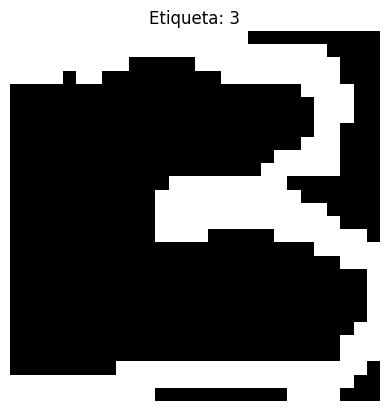

Mínimo: 0
Máximo: 255
Promedio: 66.92686396683673
[0 0 0]
True
True


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

data = np.load('/content/drive/MyDrive/Colab Notebooks/Telugu-optimized.npz')

print(data.files)

x_train = data['x_train']
y_train = data['y_train']

x_test = data['x_test']
y_test = data['y_test']

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

print("Tipo de x_train:", x_train.dtype)
print("Tipo de y_train:", y_train.dtype)

print("Valores de y_train:", np.unique(y_train))



plt.imshow(x_train[0], cmap='gray')
plt.title(f"Etiqueta: {y_train[0]}")
plt.axis('off')
plt.show()

print("Mínimo:", x_train.min())
print("Máximo:", x_train.max())
print("Promedio:", x_train.mean())

print(x_train[0, 10, 10])

print(np.array_equal(x_train[:, :, :, 0],
                     x_train[:, :, :, 1]))

print(np.array_equal(x_train[:, :, :, 1],
                     x_train[:, :, :, 2]))
#True True
#significaría que los tres canales contienen exactamente la misma información, por lo que en realidad podríamos trabajar con una imagen de un solo canal.

**normalización**

(facilita el entrenamiento de la red neuronal)

X'normalizado = x/255

*   0     → 0.0
*   128   → 0.502
*   255   → 1.0





In [ ]:
#Verificacion de dataset balanceado
print("Distribución en train:")
print(np.bincount(y_train))

print("\nDistribución en test:")
print(np.bincount(y_test))

Distribución en train:
[7997 7991 8005 8020 7974 8005 7980 8053 8000 7975]

Distribución en test:
[2003 2009 1995 1980 2026 1995 2020 1947 2000 2025]


Si el dataset no estuviera balanceado, podriamos tener casos en los que el 90% de nuestro dataset sea una sola clase, el modelo aprende esa clase unicamente y las demas no las reconoce, y nuestro Accuracy = 90%

### Entrada

Una imagen:

$$
28 \times 28 \times 3
$$

que contiene valores de píxeles entre `0` y `255`.

Cada muestra tiene:

$$
28 \times 28 \times 3 = 2352
$$

valores de entrada.

### Salida

Una etiqueta:

$$
y \in \{0,1,2,3,4,5,6,7,8,9\}
$$

## 1. `Conv2D`

La idea clave es que `Conv2D` no analiza cada píxel de manera completamente aislada. Utiliza un **filtro/kernel** que se desplaza por pequeñas regiones de la imagen, tratando de encontrar patrones en areas.

**considera regiones locales y aprende relaciones entre valores cercanos.**

---

# 2. `MaxPooling`

Reduce la dimensionalidad espacial, manteniendo la informacion importante

```text
1  3  2  1
5  7  4  2
2  1  8  3
0  2  6  1
```

Un `MaxPooling(2x2)` podría convertirlo en:

```text
7  4
2  8
```

porque toma el máximo de cada región:

Entonces:

> **Reduce el tamaño espacial conservando la activación más fuerte de cada región.**

Y sí, al reducir el tamaño:

* disminuye el costo computacional;
* reduce la cantidad de información espacial;
* puede ayudar a reducir el sobreajuste.

---

# 3. `Flatten`

es una layer que agarra nuestros datos de varias dimensiones y lo arregla en un vector, en esta capa no se aprende.

```text
28 × 28 × 3
```

Flatten lo transforma en:

```text
2352
```

---

# 4. `Dense`

Cuando llegamos a `Dense`, **ya no estamos trabajando directamente con la imagen original**.

Por ejemplo:

```text
Imagen 28×28×3
       ↓
    Conv2D
       ↓
 MaxPooling
       ↓
    Conv2D
       ↓
 MaxPooling
       ↓
    Flatten
       ↓
     Dense
```

Las `Dense` reciben las características que las capas anteriores fueron extrayendo.

> "Dadas todas estas características detectadas, ¿qué combinación corresponde a cada dígito?"

Trabaja **globalmente**.

Después de `Flatten`, tiene acceso a todas las características:

```text
[feature 1, feature 2, feature 3, ..., feature N]
```

y aprende relaciones entre ellas.


In [ ]:
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
# Normalizamos
print("x_train max:", x_train.max())
x_train = x_train / 255.0
x_test = x_test / 255.0

# Versión de un solo canal
x_train_gray = x_train[:, :, :, 0:1] #como todos los canales iguales vamos a probar algunas CNN con un solo canal
x_test_gray = x_test[:, :, :, 0:1]

# Preparamos y_train e y_test para usar One Hot Encoding
y_train_one_hot = to_categorical(y_train, num_classes=10)
y_test_one_hot = to_categorical(y_test, num_classes=10)
#print(y_train[0])
#print(y_train_one_hot[0])

#definimos 3 arquitecturas CNN para comparar

print("x_train:", x_train.shape)
print("x_train_gray:", x_train_gray.shape)

print("y_train:", y_train.shape)
print("y_train_one_hot:", y_train_one_hot.shape)

print("x_train min:", x_train.min())
print("x_train max:", x_train.max())

print("Ejemplo de y:")
print(y_train[0])
print(y_train_one_hot[0])


# Validation
# Separamos de los 80k 72 para entrenamiento 8 para validacion y despues los 20 de test.
# x_train_new, x_val = np.split(x_train, [72000]) #Esto agarra por orden y como no sabemos como estan los datos podes correr riesgo de q no esten bien distribuidos.

indices = np.arange(len(x_train))

indices_train, indices_val = train_test_split(
    indices,
    test_size=0.10, #10% de los 80.000 datos
    random_state=42, #semilla de aleatoriedad
    stratify=y_train #para mantener el balance de las clases
)
# RGB
x_train_final = x_train[indices_train]
x_val = x_train[indices_val]

# Grayscale
x_train_gray_final = x_train_gray[indices_train]
x_val_gray = x_train_gray[indices_val]

# Etiquetas One-Hot
y_train_final = y_train_one_hot[indices_train]
y_val = y_train_one_hot[indices_val]

print(x_train_final.shape)
print(x_val.shape)

print(x_train_gray_final.shape)
print(x_val_gray.shape)

print(y_train_final.shape)
print(y_val.shape)

x_train max: 255
x_train: (80000, 28, 28, 3)
x_train_gray: (80000, 28, 28, 1)
y_train: (80000,)
y_train_one_hot: (80000, 10)
x_train min: 0.0
x_train max: 1.0
Ejemplo de y:
3
[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
(72000, 28, 28, 3)
(8000, 28, 28, 3)
(72000, 28, 28, 1)
(8000, 28, 28, 1)
(72000, 10)
(8000, 10)


# CNN Modelo 1

Entrada: 28×28×3

Conv2D(32, 3×3, ReLU)   Los filtros(32) pueden aprender diferentes tipos de patrones. Cada filtro observa regiones de 3x3

MaxPooling(2×2) reduce las dimensiones espaciales aproximadamente a la mitad.

Conv2D(64, 3×3, ReLU)

MaxPooling(2×2)

Flatten

Dense(128, ReLU)

Dense(10, Softmax)

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model_1 = keras.Sequential([

    layers.Input(shape=(28, 28, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dense(10, activation='softmax')
])

model_1.compile(
    optimizer='adam', # Es el algoritmo que va modificando los pesos de la red para reducir el error.
    loss='categorical_crossentropy', # Es la función que mide qué tan diferente es: predicción de la red de: etiqueta One-Hot correcta
    metrics=['accuracy'] #Le pedimos a Keras que registre accuracy durante el entrenamiento.
)

model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,610 (881.29 KB)

 Trainable params: 225,610 (881.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
batch_size = 128
epochs = 20
history_1 = model_1.fit(x_train_final, y_train_final, validation_data=(x_val, y_val),epochs=20, batch_size=128)



Epoch 1/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 78s 136ms/step - accuracy: 0.9639 - loss: 0.1146 - val_accuracy: 0.9954 - val_loss: 0.0150
Epoch 2/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 68s 121ms/step - accuracy: 0.9972 - loss: 0.0093 - val_accuracy: 0.9974 - val_loss: 0.0076
Epoch 3/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 83s 122ms/step - accuracy: 0.9978 - loss: 0.0066 - val_accuracy: 0.9995 - val_loss: 0.0021
Epoch 4/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 92s 139ms/step - accuracy: 0.9990 - loss: 0.0027 - val_accuracy: 0.9998 - val_loss: 0.0012
Epoch 5/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 67s 118ms/step - accuracy: 0.9991 - loss: 0.0027 - val_accuracy: 1.0000 - val_loss: 4.6063e-04
Epoch 6/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 70s 124ms/step - accuracy: 0.9989 - loss: 0.0033 - val_accuracy: 0.9952 - val_loss: 0.0101
Epoch 7/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 80s 121ms/step - accuracy: 0.9983 - loss: 0.0051 - val_accuracy: 0.9998 - val_loss: 0.0011
Epoch 8/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 67s 119ms/step - accuracy: 0.9997 - los

ValueError: Arguments `target` and `output` must have the same rank (ndim). Received: target.shape=(32,), output.shape=(32, 10)

625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 1.0000 - loss: 1.2448e-05
Precisión en el conjunto de prueba: 1.0. Pérdida: 1.2447812878235709e-05
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


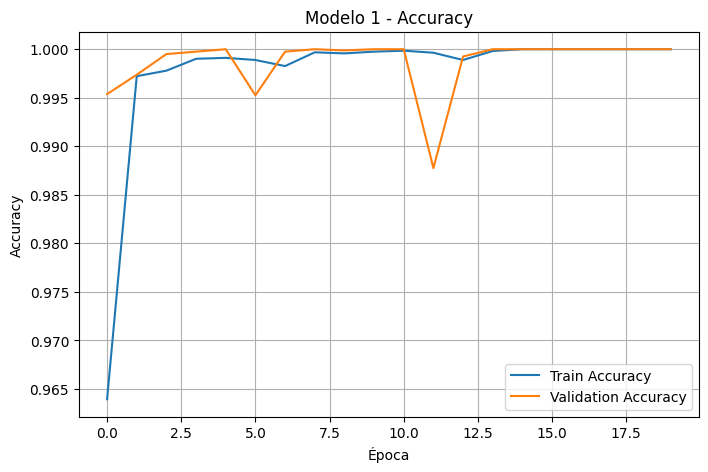

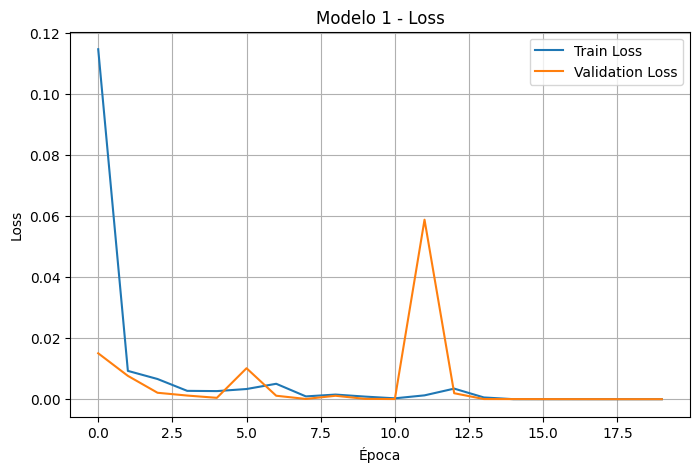

Época  1 | Train Acc: 0.9639 | Val Acc: 0.9954 | Train Loss: 0.114583 | Val Loss: 0.015039
Época  2 | Train Acc: 0.9972 | Val Acc: 0.9974 | Train Loss: 0.009277 | Val Loss: 0.007649
Época  3 | Train Acc: 0.9978 | Val Acc: 0.9995 | Train Loss: 0.006617 | Val Loss: 0.002116
Época  4 | Train Acc: 0.9990 | Val Acc: 0.9998 | Train Loss: 0.002739 | Val Loss: 0.001202
Época  5 | Train Acc: 0.9991 | Val Acc: 1.0000 | Train Loss: 0.002661 | Val Loss: 0.000461
Época  6 | Train Acc: 0.9989 | Val Acc: 0.9952 | Train Loss: 0.003343 | Val Loss: 0.010147
Época  7 | Train Acc: 0.9983 | Val Acc: 0.9998 | Train Loss: 0.005058 | Val Loss: 0.001144
Época  8 | Train Acc: 0.9997 | Val Acc: 1.0000 | Train Loss: 0.000928 | Val Loss: 0.000091
Época  9 | Train Acc: 0.9996 | Val Acc: 0.9999 | Train Loss: 0.001525 | Val Loss: 0.001134
Época 10 | Train Acc: 0.9998 | Val Acc: 1.0000 | Train Loss: 0.000855 | Val Loss: 0.000118
Época 11 | Train Acc: 0.9998 | Val Acc: 1.0000 | Train Loss: 0.000297 | Val Loss: 0.000060

In [ ]:
test_loss, test_acc = model_1.evaluate(
    x_test,
    y_test_one_hot
)

print(f'Precisión en el conjunto de prueba: {test_acc}. Pérdida: {test_loss}')

print(history_1.history.keys())

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history_1.history['accuracy'], label='Train Accuracy')
plt.plot(history_1.history['val_accuracy'], label='Validation Accuracy')

plt.title('Modelo 1 - Accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()


#Loss
plt.figure(figsize=(8, 5))

plt.plot(history_1.history['loss'], label='Train Loss')
plt.plot(history_1.history['val_loss'], label='Validation Loss')

plt.title('Modelo 1 - Loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

#Eoch comparison
for epoch in range(len(history_1.history['accuracy'])):
    print(
        f"Época {epoch+1:2d} | "
        f"Train Acc: {history_1.history['accuracy'][epoch]:.4f} | "
        f"Val Acc: {history_1.history['val_accuracy'][epoch]:.4f} | "
        f"Train Loss: {history_1.history['loss'][epoch]:.6f} | "
        f"Val Loss: {history_1.history['val_loss'][epoch]:.6f}"
    )



In [ ]:
y_pred_prob = model_1.predict(x_test)
import numpy as np

y_pred = np.argmax(y_pred_prob, axis=1)
from sklearn.metrics import precision_score, recall_score, f1_score
precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      2003
           1     1.0000    1.0000    1.0000      2009
           2     1.0000    1.0000    1.0000      1995
           3     1.0000    1.0000    1.0000      1980
           4     1.0000    1.0000    1.0000      2026
           5     1.0000    1.0000    1.0000      1995
           6     1.0000    1.0000    1.0000      2020
           7     1.0000    1.0000    1.0000      1947
           8     1.0000    1.0000    1.0000      2000
           9     1.0000    1.0000    1.0000      2025

    accuracy                         1.0000     20000
   macro avg     1.0000    1.0000    1.0000     20000
weighted avg     1.0000    1.0000    1.0000     20000



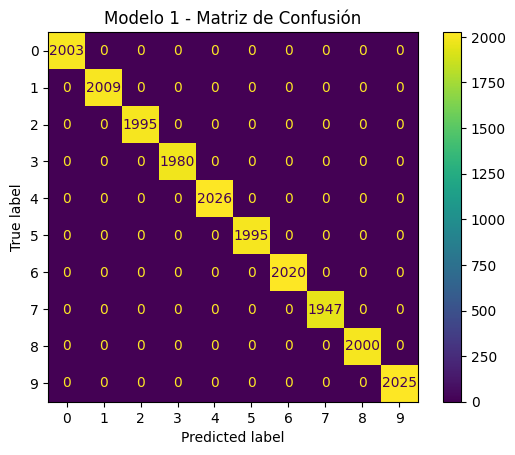

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title('Modelo 1 - Matriz de Confusión')
plt.show()

# Modelo 2

Entrada: 28×28×1

Conv2D(32, 3×3, ReLU)

MaxPooling(2×2)

Conv2D(64, 3×3, ReLU)

MaxPooling(2×2)

Flatten

Dense(128, ReLU)

Dense(10, Softmax)

In [ ]:
model_2 = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dense(10, activation='softmax')
])

model_2.compile(
    optimizer='adam', # Es el algoritmo que va modificando los pesos de la red para reducir el error.
    loss='categorical_crossentropy', # Es la función que mide qué tan diferente es: predicción de la red de: etiqueta One-Hot correcta
    metrics=['accuracy'] #Le pedimos a Keras que registre accuracy durante el entrenamiento.
)

model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_2 = model_2.fit(x_train_gray_final, y_train_final, validation_data=(x_val_gray, y_val),epochs=20, batch_size=128)

Epoch 1/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 88s 155ms/step - accuracy: 0.9592 - loss: 0.1352 - val_accuracy: 0.9925 - val_loss: 0.0210
Epoch 2/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 106s 189ms/step - accuracy: 0.9952 - loss: 0.0144 - val_accuracy: 0.9986 - val_loss: 0.0057
Epoch 3/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 129ms/step - accuracy: 0.9975 - loss: 0.0082 - val_accuracy: 0.9996 - val_loss: 0.0026
Epoch 4/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 114ms/step - accuracy: 0.9984 - loss: 0.0055 - val_accuracy: 0.9994 - val_loss: 0.0023
Epoch 5/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 80s 111ms/step - accuracy: 0.9989 - loss: 0.0034 - val_accuracy: 1.0000 - val_loss: 8.4606e-04
Epoch 6/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 63s 112ms/step - accuracy: 0.9990 - loss: 0.0032 - val_accuracy: 0.9975 - val_loss: 0.0064
Epoch 7/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 81s 110ms/step - accuracy: 0.9991 - loss: 0.0036 - val_accuracy: 0.9991 - val_loss: 0.0028
Epoch 8/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 62s 110ms/step - accuracy: 0.9990 - lo

625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9999 - loss: 8.4839e-05
Precisión en el conjunto de prueba: 0.9999499917030334. Pérdida: 8.483857527608052e-05
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


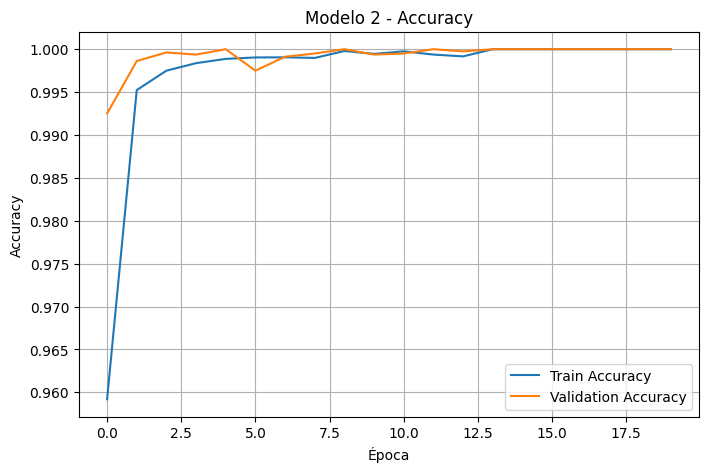

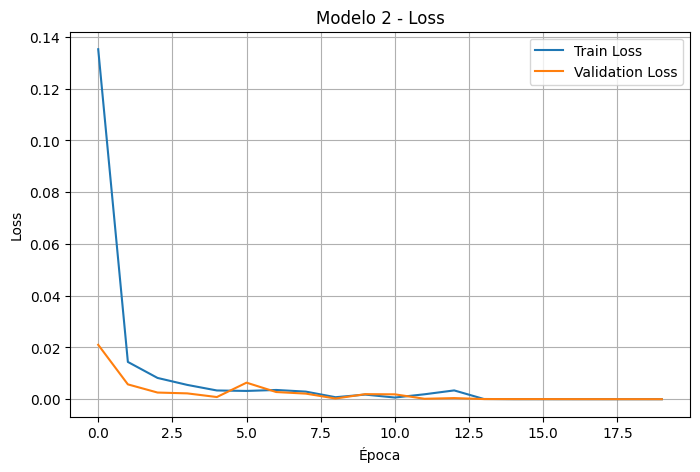

Época  1 | Train Acc: 0.9592 | Val Acc: 0.9925 | Train Loss: 0.135222 | Val Loss: 0.021033
Época  2 | Train Acc: 0.9952 | Val Acc: 0.9986 | Train Loss: 0.014412 | Val Loss: 0.005738
Época  3 | Train Acc: 0.9975 | Val Acc: 0.9996 | Train Loss: 0.008225 | Val Loss: 0.002581
Época  4 | Train Acc: 0.9984 | Val Acc: 0.9994 | Train Loss: 0.005540 | Val Loss: 0.002262
Época  5 | Train Acc: 0.9989 | Val Acc: 1.0000 | Train Loss: 0.003384 | Val Loss: 0.000846
Época  6 | Train Acc: 0.9990 | Val Acc: 0.9975 | Train Loss: 0.003205 | Val Loss: 0.006401
Época  7 | Train Acc: 0.9991 | Val Acc: 0.9991 | Train Loss: 0.003578 | Val Loss: 0.002780
Época  8 | Train Acc: 0.9990 | Val Acc: 0.9995 | Train Loss: 0.002941 | Val Loss: 0.002165
Época  9 | Train Acc: 0.9998 | Val Acc: 1.0000 | Train Loss: 0.000778 | Val Loss: 0.000274
Época 10 | Train Acc: 0.9995 | Val Acc: 0.9994 | Train Loss: 0.001790 | Val Loss: 0.001959
Época 11 | Train Acc: 0.9998 | Val Acc: 0.9995 | Train Loss: 0.000653 | Val Loss: 0.001891

In [ ]:
test_loss_2, test_acc_2 = model_2.evaluate(
    x_test_gray,
    y_test_one_hot
)

print(f'Precisión en el conjunto de prueba: {test_acc_2}. Pérdida: {test_loss_2}')

print(history_2.history.keys())

plt.figure(figsize=(8, 5))

plt.plot(history_2.history['accuracy'], label='Train Accuracy')
plt.plot(history_2.history['val_accuracy'], label='Validation Accuracy')

plt.title('Modelo 2 - Accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()


#Loss
plt.figure(figsize=(8, 5))

plt.plot(history_2.history['loss'], label='Train Loss')
plt.plot(history_2.history['val_loss'], label='Validation Loss')

plt.title('Modelo 2 - Loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

#Eoch comparison
for epoch in range(len(history_2.history['accuracy'])):
    print(
        f"Época {epoch+1:2d} | "
        f"Train Acc: {history_2.history['accuracy'][epoch]:.4f} | "
        f"Val Acc: {history_2.history['val_accuracy'][epoch]:.4f} | "
        f"Train Loss: {history_2.history['loss'][epoch]:.6f} | "
        f"Val Loss: {history_2.history['val_loss'][epoch]:.6f}"
    )

625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
              precision    recall  f1-score   support

           0     0.9995    1.0000    0.9998      2003
           1     1.0000    0.9995    0.9998      2009
           2     1.0000    1.0000    1.0000      1995
           3     1.0000    1.0000    1.0000      1980
           4     1.0000    1.0000    1.0000      2026
           5     1.0000    1.0000    1.0000      1995
           6     1.0000    1.0000    1.0000      2020
           7     1.0000    1.0000    1.0000      1947
           8     1.0000    1.0000    1.0000      2000
           9     1.0000    1.0000    1.0000      2025

    accuracy                         1.0000     20000
   macro avg     1.0000    1.0000    1.0000     20000
weighted avg     1.0000    1.0000    1.0000     20000



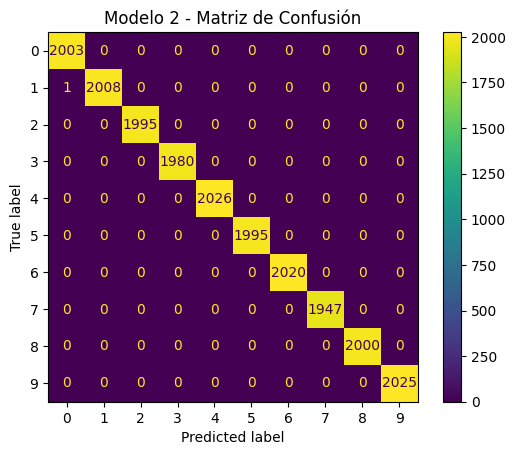

In [ ]:
y_pred_prob2 = model_2.predict(x_test_gray)
import numpy as np

y_pred = np.argmax(y_pred_prob2, axis=1)
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


print(classification_report(
    y_test,
    y_pred,
    digits=4
))



cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title('Modelo 2 - Matriz de Confusión')
plt.show()

Entrada: 28×28×1

Conv2D(32, 3×3, ReLU)

MaxPooling(2×2)

Conv2D(64, 3×3, ReLU)

MaxPooling(2×2)

Conv2D(128, 3×3, ReLU)

Flatten

Dense(128, ReLU)

Dense(10, Softmax)

In [ ]:
model_3 = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dense(10, activation='softmax')
])

model_3.compile(
    optimizer='adam', # Es el algoritmo que va modificando los pesos de la red para reducir el error.
    loss='categorical_crossentropy', # Es la función que mide qué tan diferente es: predicción de la red de: etiqueta One-Hot correcta
    metrics=['accuracy'] #Le pedimos a Keras que registre accuracy durante el entrenamiento.
)

model_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,546 (943.54 KB)

 Trainable params: 241,546 (943.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_3 = model_3.fit(x_train_gray_final, y_train_final, validation_data=(x_val_gray, y_val),epochs=20, batch_size=128)

Epoch 1/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 73s 126ms/step - accuracy: 0.9515 - loss: 0.1453 - val_accuracy: 0.9973 - val_loss: 0.0121
Epoch 2/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 84s 130ms/step - accuracy: 0.9954 - loss: 0.0133 - val_accuracy: 0.9994 - val_loss: 0.0035
Epoch 3/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 81s 127ms/step - accuracy: 0.9971 - loss: 0.0098 - val_accuracy: 0.9946 - val_loss: 0.0144
Epoch 4/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 69s 122ms/step - accuracy: 0.9976 - loss: 0.0071 - val_accuracy: 0.9987 - val_loss: 0.0037
Epoch 5/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 84s 125ms/step - accuracy: 0.9992 - loss: 0.0025 - val_accuracy: 0.9990 - val_loss: 0.0023
Epoch 6/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 82s 125ms/step - accuracy: 0.9980 - loss: 0.0055 - val_accuracy: 1.0000 - val_loss: 4.1387e-04
Epoch 7/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 71s 125ms/step - accuracy: 0.9989 - loss: 0.0038 - val_accuracy: 1.0000 - val_loss: 7.3292e-04
Epoch 8/20
563/563 ━━━━━━━━━━━━━━━━━━━━ 69s 122ms/step - accuracy: 0.9990 -

625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9999 - loss: 2.3211e-04
Precisión en el conjunto de prueba: 0.9999499917030334. Pérdida: 0.00023211067309603095
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


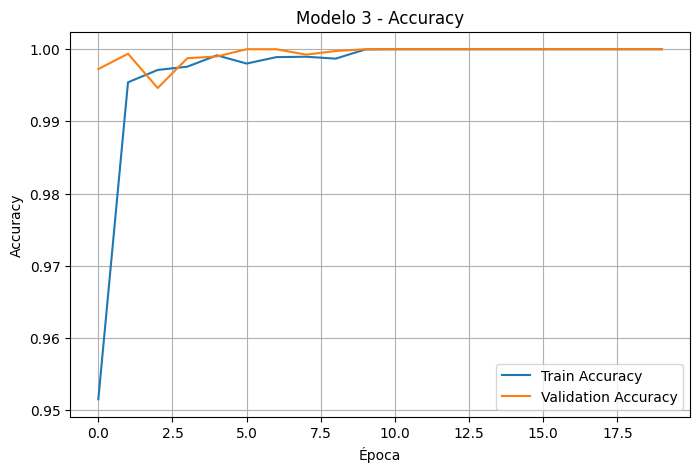

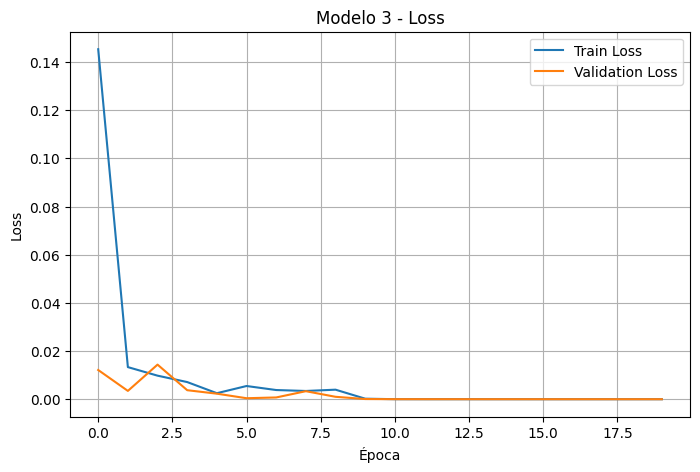

Época  1 | Train Acc: 0.9515 | Val Acc: 0.9973 | Train Loss: 0.145316 | Val Loss: 0.012130
Época  2 | Train Acc: 0.9954 | Val Acc: 0.9994 | Train Loss: 0.013334 | Val Loss: 0.003454
Época  3 | Train Acc: 0.9971 | Val Acc: 0.9946 | Train Loss: 0.009784 | Val Loss: 0.014367
Época  4 | Train Acc: 0.9976 | Val Acc: 0.9987 | Train Loss: 0.007124 | Val Loss: 0.003747
Época  5 | Train Acc: 0.9992 | Val Acc: 0.9990 | Train Loss: 0.002501 | Val Loss: 0.002302
Época  6 | Train Acc: 0.9980 | Val Acc: 1.0000 | Train Loss: 0.005486 | Val Loss: 0.000414
Época  7 | Train Acc: 0.9989 | Val Acc: 1.0000 | Train Loss: 0.003814 | Val Loss: 0.000733
Época  8 | Train Acc: 0.9990 | Val Acc: 0.9992 | Train Loss: 0.003426 | Val Loss: 0.003332
Época  9 | Train Acc: 0.9987 | Val Acc: 0.9998 | Train Loss: 0.003964 | Val Loss: 0.001006
Época 10 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000220 | Val Loss: 0.000078
Época 11 | Train Acc: 1.0000 | Val Acc: 1.0000 | Train Loss: 0.000018 | Val Loss: 0.000022

In [ ]:
test_loss_3, test_acc_3 = model_3.evaluate(
    x_test_gray,
    y_test_one_hot
)

print(f'Precisión en el conjunto de prueba: {test_acc_3}. Pérdida: {test_loss_3}')

print(history_3.history.keys())

plt.figure(figsize=(8, 5))

plt.plot(history_3.history['accuracy'], label='Train Accuracy')
plt.plot(history_3.history['val_accuracy'], label='Validation Accuracy')

plt.title('Modelo 3 - Accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

#Loss
plt.figure(figsize=(8, 5))

plt.plot(history_3.history['loss'], label='Train Loss')
plt.plot(history_3.history['val_loss'], label='Validation Loss')

plt.title('Modelo 3 - Loss')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

#Eoch comparison
for epoch in range(len(history_3.history['accuracy'])):
    print(
        f"Época {epoch+1:2d} | "
        f"Train Acc: {history_3.history['accuracy'][epoch]:.4f} | "
        f"Val Acc: {history_3.history['val_accuracy'][epoch]:.4f} | "
        f"Train Loss: {history_3.history['loss'][epoch]:.6f} | "
        f"Val Loss: {history_3.history['val_loss'][epoch]:.6f}"
    )

625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
              precision    recall  f1-score   support

           0     0.9995    1.0000    0.9998      2003
           1     1.0000    0.9995    0.9998      2009
           2     1.0000    1.0000    1.0000      1995
           3     1.0000    1.0000    1.0000      1980
           4     1.0000    1.0000    1.0000      2026
           5     1.0000    1.0000    1.0000      1995
           6     1.0000    1.0000    1.0000      2020
           7     1.0000    1.0000    1.0000      1947
           8     1.0000    1.0000    1.0000      2000
           9     1.0000    1.0000    1.0000      2025

    accuracy                         1.0000     20000
   macro avg     1.0000    1.0000    1.0000     20000
weighted avg     1.0000    1.0000    1.0000     20000



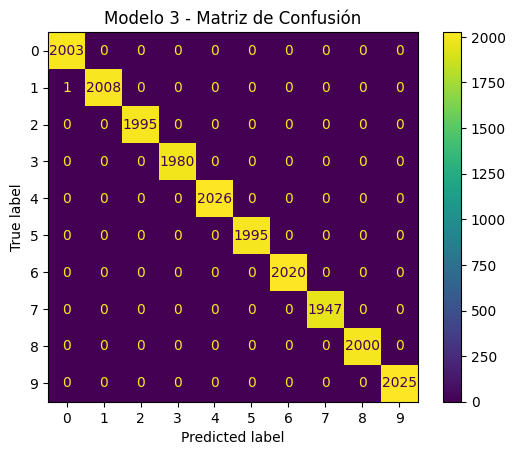

In [ ]:
y_pred_prob3 = model_3.predict(x_test_gray)
import numpy as np

y_pred = np.argmax(y_pred_prob3, axis=1)
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


print(classification_report(
    y_test,
    y_pred,
    digits=4
))



cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title('Modelo 3 - Matriz de Confusión')
plt.show()